# Inserting glitch in wave - first test

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from gwpy.timeseries import TimeSeries
from glitchgan import GlitchGAN, scale_for_injection

# H1_250114
START_TIME = 1420877824 

from gwosc.datasets import event_gps
MERGER_TIME = event_gps('GW250114_082203')
duration = 32
START_TIME = MERGER_TIME-duration/2

ts = TimeSeries.fetch_open_data(
    "H1",
    START_TIME,
    START_TIME + duration,
)

SAMPLE_RATE = len(ts) / duration #how many data points per second
print(SAMPLE_RATE)

mask = np.isfinite(ts.value)
ts = ts[mask]

#psd = ts.psd()

strain_signal = ts.value #strain as numpy array
t = ts.times.value -START_TIME #time array starting from 0 

DURATION = round(np.max(t)) #different from "duration", because the data was cut when we removed nan values.

4096.0


In [115]:
model = GlitchGAN.from_pretrained()
GLITCH_CLASS = "Blip"   # change to any of model.CLASSES
TARGET_SNR   = 30     # matched-filter SNR after injection

# Raw, normalised generator output — no amplitude scaling yet
glitch_raw = model.generate(GLITCH_CLASS, n=1)[0] #generate 1 glitch from that class

print(f"Generated {GLITCH_CLASS}: {glitch_raw.shape} samples at {SAMPLE_RATE} Hz")

# Frequency grid of the glitch
# glitch_freqs = np.fft.rfftfreq(len(glitch_raw), d=1.0 / SAMPLE_RATE)

# # Interpolate PSD onto the glitch frequencies
# psd_interp = np.interp(
#     glitch_freqs,
#     psd.frequencies.value,
#     psd.value,
# )

# # Remove invalid frequencies
# psd_interp = np.where(
#     np.isfinite(psd_interp) & (psd_interp > 0),
#     psd_interp,
#     0.0,
# )

# # Ignore frequencies below 20 Hz
# psd_interp[glitch_freqs < 20] = 0.0

# dividing by WHITEN_NORM converts to the GWpy/GW-community convention (RMS ≈ 1). 
WHITEN_NORM = np.sqrt(SAMPLE_RATE / 2) 

n_segment = len(strain_signal)
onset_dt = duration/2-0.02 #317.2 # seconds from t0. choosing a time close to where the signal also peaks.
onset_sample = int(onset_dt * SAMPLE_RATE) #corresponding index in time array.

print(n_segment)
print(onset_sample)


ONSET_TIME = START_TIME + onset_sample/SAMPLE_RATE

Generated Blip: (8192,) samples at 4096.0 Hz
131072
65454


In [116]:
def _pad_glitch(glitch_1d, n_segment, onset_sample):
    """Zero-pad glitch_1d so its peak falls at onset_sample."""
    padded   = np.zeros(n_segment)
    peak_idx = int(np.argmax(np.abs(glitch_1d)))
    start    = onset_sample - peak_idx
    end      = start + len(glitch_1d)
    seg_s    = max(0, start)
    seg_e    = min(n_segment, end)
    src_s    = seg_s - start
    padded[seg_s:seg_e] = glitch_1d[src_s : src_s + (seg_e - seg_s)]
    return padded

In [117]:
# 1. Scale glitch_raw to TARGET_SNR in the whitened frame
_g = glitch_raw.astype(np.float64)

_df = SAMPLE_RATE / len(_g)

_sigma_sq = 4.0 * _df * np.sum(np.abs(np.fft.rfft(_g) / SAMPLE_RATE) ** 2)

glitch_white_scaled = (_g * TARGET_SNR / np.sqrt(_sigma_sq)).astype(np.float32)

strain_signal_white = ts.whiten().value #THIS STEP MIGHT BE WRONG!



In [118]:
# 3. Inject — both in the whitened frame

glitch_white_padded   = _pad_glitch(glitch_white_scaled / WHITEN_NORM, n_segment, onset_sample)
strain_white_injected = strain_signal_white + glitch_white_padded

print(f"Whitened noise RMS:   {np.std(strain_signal_white):.4f}  (unit-variance)")
print(f"Whitened glitch peak: {np.max(np.abs(glitch_white_padded)):.4f}  (unit-variance)")

print(WHITEN_NORM,n_segment,onset_sample)

Whitened noise RMS:   1.0017  (unit-variance)
Whitened glitch peak: 12.4518  (unit-variance)
45.254833995939045 131072 65454


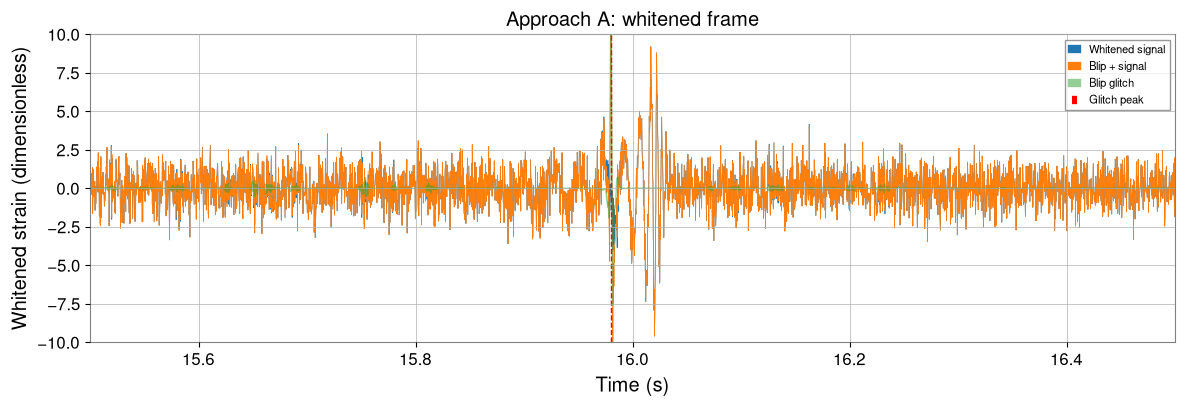

In [119]:
# ── Time-series: both approaches with glitch overlaid ────────────────────────
fig, ax = plt.subplots(figsize=(14, 4))

# Approach A: whitened frame
ax.plot(t, strain_signal_white, color="C0", lw=0.5, label=f"Whitened signal")
ax.plot(t, strain_white_injected, color="C1", lw=0.5, label=f"{GLITCH_CLASS} + signal")
ax.plot(t, glitch_white_padded,   color="C2", lw=1.0, label=f"{GLITCH_CLASS} glitch",alpha=0.5)
ax.axvline(ONSET_TIME - START_TIME, color="red", ls="--", lw=1, label="Glitch peak")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Whitened strain (dimensionless)")
ax.set_title("Approach A: whitened frame")
plt.xlim(duration/2-dt,duration/2+dt)
plt.ylim(-10,10)
ax.legend(fontsize=8)

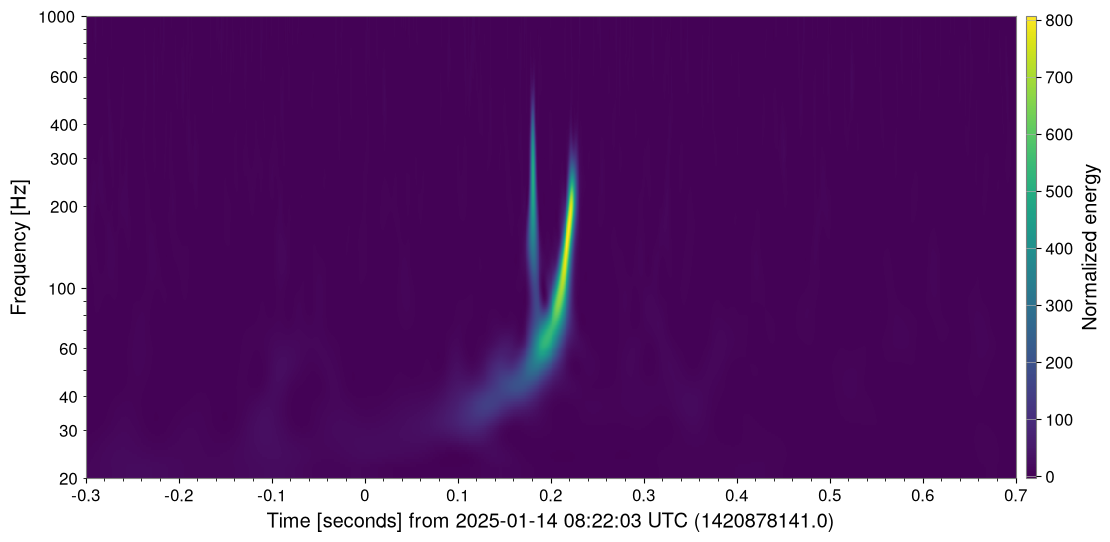

In [120]:
ts2 = TimeSeries(
    strain_white_injected,
    sample_rate=SAMPLE_RATE,
    t0=START_TIME,
    unit="strain",
)

dt = 0.5 #-- Set width of q-transform plot, in seconds
hq = ts2.q_transform(outseg=(MERGER_TIME-dt,MERGER_TIME+dt),frange=(20,1000)) 
fig4 = hq.plot()
ax = fig4.gca()
ax.grid(False)
ax.set_yscale('log')
fig4.colorbar(label="Normalized energy")

# Inserting glitch in wave - automated

I0000 00:00:1787937197.092423     224 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1787937201.979370     224 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1787937207.410189     224 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
/home/izumitakimoto.schmiegelow/.conda/envs/glitchgan_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
E0000 00:00:1787937209.513315     224 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


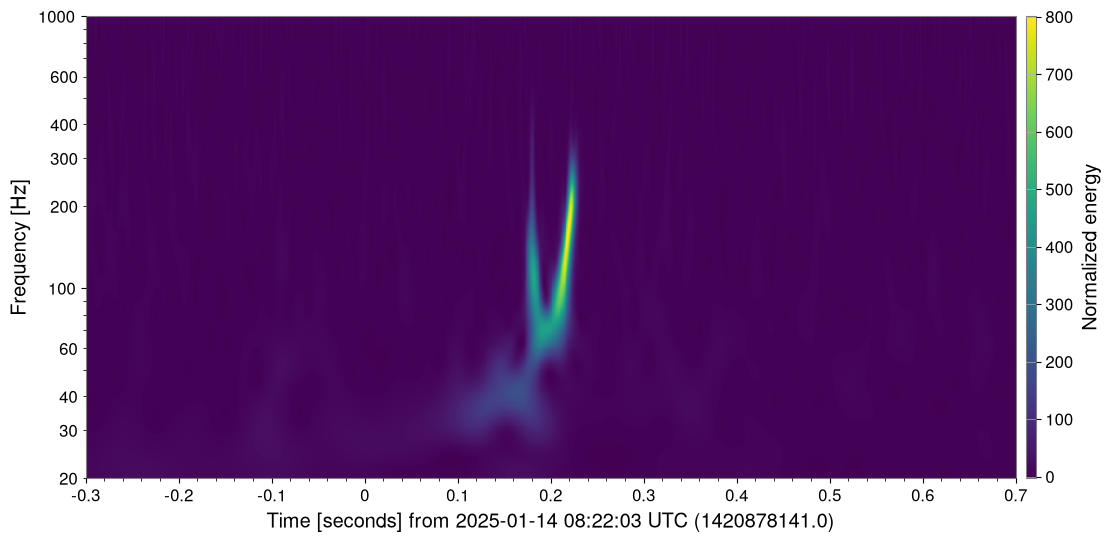

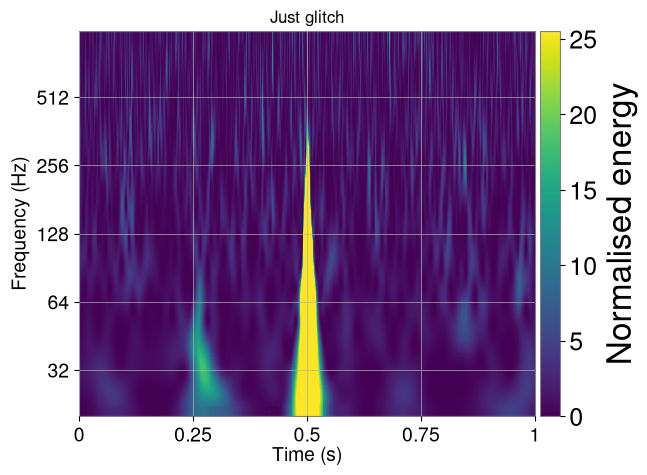

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from gwpy.timeseries import TimeSeries
from glitchgan import GlitchGAN, scale_for_injection
from gwosc.datasets import event_gps
import bilby
from glitchgan.utils import plot_q_transform


def _pad_glitch(glitch_1d, n_segment, onset_sample):
    """Zero-pad glitch_1d so its peak falls at onset_sample."""
    padded   = np.zeros(n_segment)
    peak_idx = int(np.argmax(np.abs(glitch_1d)))
    start    = onset_sample - peak_idx
    end      = start + len(glitch_1d)
    seg_s    = max(0, start)
    seg_e    = min(n_segment, end)
    src_s    = seg_s - start
    padded[seg_s:seg_e] = glitch_1d[src_s : src_s + (seg_e - seg_s)]
    return padded

def plot_just_glitch(glitch_type, glitch_SNR): #basically glitchGAN's tutorial
    model = GlitchGAN.from_pretrained()
    GLITCH_CLASS = glitch_type   # change to any of model.CLASSES
    SAMPLE_RATE  = 4096.0   # Hz — GlitchGAN native rate
    TARGET_SNR   = glitch_SNR    # matched-filter SNR after injection
    
    # Raw, normalised generator output — no amplitude scaling yet
    glitch_raw = model.generate(GLITCH_CLASS, n=1)[0] #generate 1 glitch from that class
    glitch_times = np.arange(len(glitch_raw)) / SAMPLE_RATE #time array, in s, with 0 at first data point.

    #Set up a bilby interferometer with Gaussian noise
    bilby.core.utils.random.seed(42) #when bilby relies on random number generation, it will generate the same sequence every time, so it's reproducible.
    #we can choose any other random number instead of 42. that's just a common choice.
    
    DURATION   = 4.0    # seconds of detector data
    START_TIME = 0.0    # GPS start time (arbitrary for this tutorial)
    
    ifo = bilby.gw.detector.get_empty_interferometer("H1") #Get an interferometer with standard parameters for known detectors.
    ifo.set_strain_data_from_power_spectral_density( #generate a mock realization of Gaussian noise for a gravitational-wave interferometer. 
        sampling_frequency=SAMPLE_RATE,              #This populates the detector's strain data based on its Power Spectral Density.
        duration=DURATION,
        start_time=START_TIME,
    ) 

    # PSD interpolated to the glitch's frequency bins (df = 0.5 Hz, 4097 bins)
    glitch_freqs = np.fft.rfftfreq(len(glitch_raw), d=1.0 / SAMPLE_RATE)
    psd_interp   = np.interp(glitch_freqs, ifo.frequency_array,
                              ifo.power_spectral_density_array)
    # bilby sets PSD to inf/NaN at DC and below-band frequencies — zero those out
    # so sqrt(psd_interp) is finite everywhere (no signal power injected at those bins)
    psd_interp = np.where(np.isfinite(psd_interp) & (psd_interp > 0), psd_interp, 0.0)
    # Also zero below the detector's sensitive band: the seismic wall (10–20 Hz) has
    # large-but-finite PSD values that would corrupt the colouring in Approach B.
    psd_interp[glitch_freqs < ifo.minimum_frequency] = 0.0
    
    # Unit-variance normalisation: numpy irfft gives RMS = sqrt(fs/2) ≈ 45.25;
    # dividing by WHITEN_NORM converts to the GWpy/GW-community convention (RMS ≈ 1).
    WHITEN_NORM = np.sqrt(SAMPLE_RATE / 2)
    
    ONSET_TIME   = START_TIME + DURATION / 2
    strain_noise = ifo.time_domain_strain.copy()
    n_segment    = len(ifo.time_array)
    onset_sample = int((ONSET_TIME - START_TIME) * SAMPLE_RATE)

    # 1. Scale glitch_raw to TARGET_SNR in the whitened frame
    #    (same realization as Approach B — only the injection frame differs)
    _g = glitch_raw.astype(np.float64)
    _df = SAMPLE_RATE / len(_g)
    _sigma_sq = 4.0 * _df * np.sum(np.abs(np.fft.rfft(_g) / SAMPLE_RATE) ** 2)
    glitch_white_scaled = (_g * TARGET_SNR / np.sqrt(_sigma_sq)).astype(np.float32)
    
    # 2. Whiten the bilby noise: h_white(f) = h_strain(f) / sqrt(S_n(f))
    #    Divide by WHITEN_NORM for unit-variance output (RMS ≈ 1, GW community convention)
    noise_white_fd     = ifo.frequency_domain_strain / np.sqrt(ifo.power_spectral_density_array)
    strain_noise_white = np.fft.irfft(noise_white_fd * SAMPLE_RATE, n=n_segment) / WHITEN_NORM
    
    # 3. Inject — both in the whitened frame
    glitch_white_padded   = _pad_glitch(glitch_white_scaled / WHITEN_NORM, n_segment, onset_sample)
    strain_white_injected = strain_noise_white + glitch_white_padded

    #plot
    CROP    = 0.5
    Q_RANGE = (4, 64)
    F_RANGE = (20, 1000)
    
    fig, ax = plt.subplots(figsize=(7, 5))
    
    plot_q_transform(
        strain_white_injected,
        srate=SAMPLE_RATE,
        crop=(ONSET_TIME, 2 * CROP),
        whiten=False,
        qrange=Q_RANGE,
        frange=F_RANGE,
        ax=ax,
    )
    
    ax.set_title("Just glitch", fontsize=12)
    plt.show()
    return

def plot_injected_signal(strain_white_injected, START_TIME, SAMPLE_RATE,MERGER_TIME):
    #make q-transform plot:
    ts2 = TimeSeries(
    strain_white_injected,
    sample_rate=SAMPLE_RATE,
    t0=START_TIME,
    unit="strain",
    )
    
    dt = 0.5 # Set width of q-transform plot, in seconds
    hq = ts2.q_transform(outseg=(MERGER_TIME-dt,MERGER_TIME+dt),frange=(20,1000)) 
    fig4 = hq.plot()
    ax = fig4.gca()
    ax.grid(False)
    ax.set_yscale('log')
    fig4.colorbar(label="Normalized energy")
    
    return
    
def generate_signal(event, detector, glitch_type, glitch_SNR, offset):

    #create a time series with the event data:
    MERGER_TIME = event_gps(event)
    duration = 32
    START_TIME = MERGER_TIME-duration/2
    
    ts = TimeSeries.fetch_open_data(
        detector,
        START_TIME,
        START_TIME + duration,
    )
    
    SAMPLE_RATE = len(ts) / duration #how many data points per second

    #remove nans from data:
    mask = np.isfinite(ts.value)
    ts = ts[mask]
    
    #get the strain and time arrays:
    strain_signal = ts.value #strain as numpy array
    t = ts.times.value -START_TIME #time array starting from 0 
    
    DURATION = round(np.max(t)) #different from "duration", because the data was cut when we removed nan values.

    model = GlitchGAN.from_pretrained()
    
    # Raw, normalised generator output — no amplitude scaling yet
    glitch_raw = model.generate(glitch_type, n=1)[0] #generate 1 glitch from that class
        
    WHITEN_NORM = np.sqrt(SAMPLE_RATE / 2) 
    
    n_segment = len(strain_signal)
    onset_dt = duration/2 +offset #317.2 # seconds from t0. choosing a time close to where the signal also peaks.
    onset_sample = int(onset_dt * SAMPLE_RATE) #corresponding index in time array.

    ONSET_TIME = START_TIME + onset_sample/SAMPLE_RATE

    #Scale glitch_raw to target SNR in the whitened frame:
    _g = glitch_raw.astype(np.float64)
    
    _df = SAMPLE_RATE / len(_g)
    
    _sigma_sq = 4.0 * _df * np.sum(np.abs(np.fft.rfft(_g) / SAMPLE_RATE) ** 2)
    
    glitch_white_scaled = (_g * glitch_SNR / np.sqrt(_sigma_sq)).astype(np.float32)

    #whiten signal data:
    strain_signal_white = ts.whiten().value #THIS STEP MIGHT BE WRONG!

    #Inject — both in the whitened frame
    glitch_white_padded   = _pad_glitch(glitch_white_scaled / WHITEN_NORM, n_segment, onset_sample)
    strain_white_injected = strain_signal_white + glitch_white_padded

    plot_injected_signal(strain_white_injected, START_TIME, SAMPLE_RATE,MERGER_TIME)

    return #make it return data
    
event = "GW250114_082203"
detector = "H1"
glitch_type = "Koi_Fish" # choice between ['Blip', 'Fast_Scattering', 'Koi_Fish', 'Low_Frequency_Burst', 'Scattered_Light', 'Tomte', 'Whistle']
glitch_SNR = 30 # matched-filter SNR after injection
offset = -0.02 # offset, in s, between glitch peak and wave merger

generate_signal(event, detector, glitch_type, glitch_SNR, offset)
plot_just_glitch(glitch_type, glitch_SNR)
